In [1]:
%load_ext rpy2.ipython

In [2]:
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]

In [3]:
%%R -i x,y -o slope,intercept

model <- lm(y ~ x)
slope <- coef(model)[2]
intercept <- coef(model)[1]
print(paste("The slope is", slope, "and the intercept is", intercept))

[1] "The slope is 2 and the intercept is 0"


In [6]:
%%R

#load library
library(yogiroc)
library(data.table)

# -------------------------------------------------------------------------
# 1) Obtain scores and reference set (annotated patho. and bengin variants)
# -------------------------------------------------------------------------

FunctionalScores<-fread("SOD1.csv")
FunctionalScores <- FunctionalScores[, .(hgvs_pro, score)]
#FunctionalScores$duplicate<-FunctionalScores$score # Example of additional dataset
FunctionalScores$score <- FunctionalScores$score *-1
#FunctionalScores$duplicate <- FunctionalScores$duplicate*-1

ReferenceSet<-fread("referenceSet.csv")
ReferenceSet[, Pathogenic := ifelse(referenceSet == "Negative", FALSE, TRUE)]

prcdata<-merge(FunctionalScores, ReferenceSet, by = "hgvs_pro")
prcdata <- prcdata[, .(Pathogenic, score)]
prcdata<-na.omit(prcdata)

names(prcdata)[2] <- "SOD1" 
#names(prcdata)[3] <- "SOD1"  #Add curve for additional dataset like this

#create yogiroc objects for the predictions in the data
yrobj <- yr2(truth=prcdata$Pathogenic,scores=prcdata[,-1])

#Automatically saves plot into folder with indicated name
pdf(file="test.pdf", width=5.5, height=5.5)

#draw the PRC curve(s)
draw.prc(yrobj, balanced=TRUE, main="")

abline(h=90, lty="dashed")

dev.off()

png 
  2 


In [2]:
import sys
import numpy as np
import pandas as pd

sys.path.insert(1, "scripts/")
from yogiroc import *

YogiROC object
Reference set size: 18
Predictors: pred1, pred2


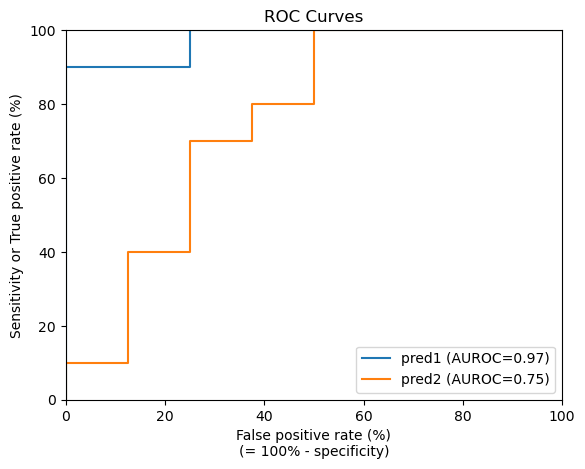

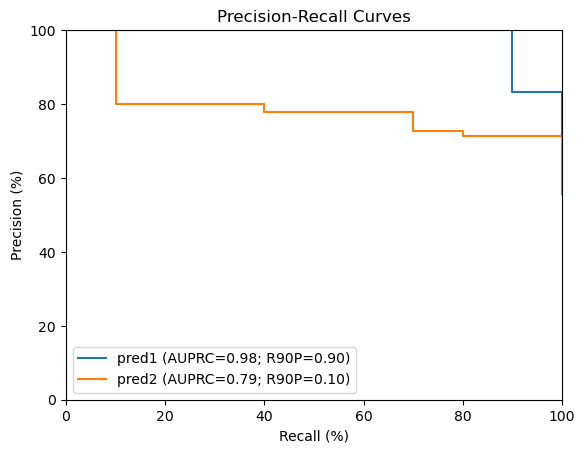

Sampling PRC paths: 100%|██████████| 18/18 [00:00<00:00, 6387.26it/s]


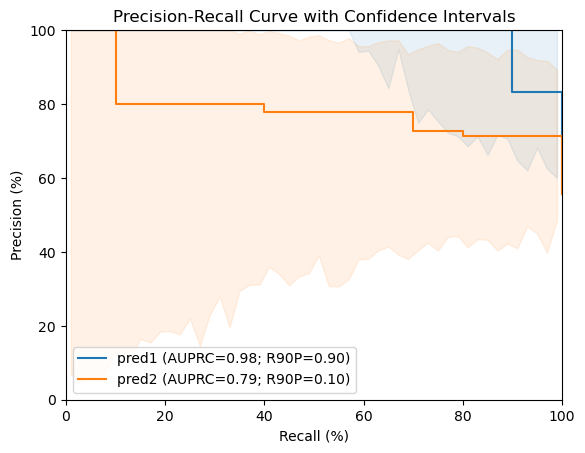

AUROC: {'pred1': 0.975, 'pred2': 0.75}
AUPRC: {'pred1': 0.9833333333333333, 'pred2': 0.788917748917749}
Recall at 90% Precision: {'pred1': 0.9, 'pred2': 0.1}


Sampling null AUPRC: 100%|██████████| 1000/1000 [00:00<00:00, 5268.80it/s]

AUPRC p-values vs. random: {'pred1': 0.0, 'pred2': 0.009}


In [3]:
# Generate fake data
np.random.seed(42)
truth = np.array([True] * 10 + [False] * 8)
# Generate scores for two predictors
pred1 = np.concatenate((np.random.normal(1, 0.2, 10), np.random.normal(0.9, 0.1, 8)))
pred2 = np.concatenate((np.random.normal(1.1, 0.2, 10), np.random.normal(0.9, 0.2, 8)))
scores = pd.DataFrame({'pred1': pred1, 'pred2': pred2})

# Create YogiROC2 object
yroc_obj = YogiROC2(truth, scores)
print(yroc_obj)

# Draw ROC and PRC curves
draw_roc(yroc_obj)
draw_prc(yroc_obj)
draw_prc_CI(yroc_obj, sampling="accurate")

# Compute AUROC and AUPRC
print("AUROC:", auroc(yroc_obj))
print("AUPRC:", auprc(yroc_obj))
print("Recall at 90% Precision:", recall_at_prec(yroc_obj))

# Assess significance against random guessing
pvals_random = auprc_pvrandom(yroc_obj, cycles=1000)  # using fewer cycles for speed
print("AUPRC p-values vs. random:", pvals_random)